# Prerequisites: Dataset and Dependencies

Install and import all required dependencies

In [1]:
%pip install -q huggingface_hub pgserver==0.1.4

In [2]:
from huggingface_hub import snapshot_download
import pandas as pd

import pgserver
from pathlib import Path

Download MovieLens 100k dataset (it is available on HuggingFace; original source had some technical issues)

In [3]:
dataset_dir = snapshot_download(
    repo_id="includeno/movielens-100k",
    repo_type="dataset",
    local_dir="data/ml-100k"
)

print(dataset_dir)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 25 files:   0%|          | 0/25 [00:00<?, ?it/s]

/content/data/ml-100k


# Task 1. Analyze Dataset and Prepare ERD

Load data from downloaded files into dataframes

In [4]:
base = "data/ml-100k/"

users = pd.read_csv(
    base + "u.user",
    sep="|",
    header=None,
    names=["user_id", "age", "gender", "occupation", "zip_code"],
    dtype={"zip_code": "string"}
)

genres = pd.read_csv(
    base + "u.genre",
    sep="|",
    header=None,
    names=["genre_name", "genre_id"]
)

genre_columns = genres.sort_values("genre_id")["genre_name"].tolist()

display(genres)

movies = pd.read_csv(
    base + "u.item",
    sep="|",
    header=None,
    names=[
        "movie_id",
        "movie_title",
        "release_date",
        "video_release_date",
        "IMDb_URL",
        *genre_columns
    ],
    encoding="latin-1"
)

ratings = pd.read_csv(
    base + "u.data",
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"]
)

,genre_name,genre_id
0,unknown,0
1,Action,1
2,Adventure,2
3,Animation,3
4,Children's,4
5,Comedy,5
6,Crime,6
7,Documentary,7
8,Drama,8
9,Fantasy,9


Analyze available entities and their fields.

In [5]:
display(users.head())
display(movies.head())
display(ratings.head())

print(users.shape)
print(movies.shape)
print(ratings.shape)

users.info()
movies.info()
ratings.info()

,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


,movie_id,movie_title,release_date,video_release_date,IMDb_URL,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


(943, 5)
(1682, 24)
(100000, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 943 entries, 0 to 942
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     943 non-null    int64 
 1   age         943 non-null    int64 
 2   gender      943 non-null    object
 3   occupation  943 non-null    object
 4   zip_code    943 non-null    string
dtypes: int64(2), object(2), string(1)
memory usage: 37.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_id            1682 non-null   int64  
 1   movie_title         1682 non-null   object 
 2   release_date        1681 non-null   object 
 3   video_release_date  0 non-null      float64
 4   IMDb_URL            1679 non-null   object 
 5   unknown             1682 non-null   int64  
 6   Action            

The dataset contains 100,000 ratings from 943 users for 1,682 movies. We can identify three basic entities: Users, Movies, and Ratings.

The dataset also includes 19 genre categories. We can model Genres as a separate entity.

Users have 5 attributes:
*  user_id (looks like candidate primary key (PK) in users)
*  age
*  gender
*  occupation
*  zip_code

Movies have 5 metadata attributes, including movie_id as a candidate for movies PK. The remaining 19 columns represent movie genre flags.

Ratings have 4 attributes. At first glance, Ratings may use a composite primary key (user_id, movie_id).

Genres have only two attributes, including genre_id as a PK candidate.

Since movies can belong to multiple genres, we can use a bridge table (Movie_Genres) to represent the many-to-many relationship. This table allows us to represent genres separately from the Movies table.

We should check the following:

*  uniqueness of candidate PK values
*  correspondence of user_id and movie_id values in users / movies and ratings
*  values of genre flags (to be sure that they are binary)
*  existing values of rating (to verify that they are integers from 1 to 5)

Convert Unix timestamps to UTC datetime values

This allows us to work with actual dates instead of integer timestamps, which will be useful for historical features and point-in-time joins

In [6]:
pd.to_datetime(ratings["timestamp"], unit="s", utc=True).head()

,timestamp
0,1997-12-04 15:55:49+00:00
1,1998-04-04 19:22:22+00:00
2,1997-11-07 07:18:36+00:00
3,1997-11-27 05:02:03+00:00
4,1998-02-02 05:33:16+00:00


Check our PK candidates for duplicates

In [7]:
display(sum(users['user_id'].duplicated()))
display(sum(movies['movie_id'].duplicated()))
display(sum(ratings[['user_id', 'movie_id']].duplicated()))

0

0

0

Check referential integrity: do all user_id and movie_id values in Ratings exist in Users and Movies?

In [8]:
unknown_users = ratings[
    ~ratings["user_id"].isin(users["user_id"])
]

print("Ratings with unknown users:", len(unknown_users))

unknown_movies = ratings[
    ~ratings["movie_id"].isin(movies['movie_id'])
]

print("Ratings with unknown movies:", len(unknown_movies))

Ratings with unknown users: 0
Ratings with unknown movies: 0


Check for missing values

In [9]:
for name, df in {
    "Users": users,
    "Movies": movies,
    "Ratings": ratings
}.items():
    print(f"\n{name}:")
    print(df.isna().sum())


Users:
user_id       0
age           0
gender        0
occupation    0
zip_code      0
dtype: int64

Movies:
movie_id                 0
movie_title              0
release_date             1
video_release_date    1682
IMDb_URL                 3
unknown                  0
Action                   0
Adventure                0
Animation                0
Children's               0
Comedy                   0
Crime                    0
Documentary              0
Drama                    0
Fantasy                  0
Film-Noir                0
Horror                   0
Musical                  0
Mystery                  0
Romance                  0
Sci-Fi                   0
Thriller                 0
War                      0
Western                  0
dtype: int64

Ratings:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


Missing values were found only in release_date, video_release_date, and IMDb_URL. The video_release_date column is completely empty, so we can exclude it from our database schema.

Check if genre parameters have only binary values (0, 1)

In [10]:
movies[genre_columns].stack().unique()

array([0, 1])

All genre flags contain only 0 and 1.

Check how many genres each movie has

In [11]:
genre_counts = movies[genre_columns].sum(axis=1)

print(genre_counts.value_counts().sort_index())

1    833
2    569
3    215
4     51
5     11
6      3
Name: count, dtype: int64


A movie may belong to multiple genres (up to 6 in this dataset)

Check available rating values and count them

In [12]:
ratings["rating"].value_counts().sort_index()

,count
rating,
1,6110
2,11370
3,27145
4,34174
5,21201


All ratings are integers from 1 to 5

Now we can create an ER diagram for the planned database.

We will create 5 tables in the business layer:

*  users (user_id as PK)
*  movies (movie_id as PK)
*  ratings (composite PK - (user_id, movie_id))
*  genres (genre_id as PK)
*  movie_genres (bridge table for movies and genres)

Required table relations:
*  users <-> ratings: 1:N (Optional)
*  movies <-> ratings: 1:N (Optional)
*  movies <-> movie_genres: 1:N (Mandatory; movie always has a genre)
*  genres <-> movie_genres: 1:N (Optional)

Each rating record must reference an existing user and movie.

Our **ML task is to predict the rating (1-5)** that a user would give to a movie. We will use historical user rating statistics as features and the actual rating as the target. Since MovieLens does not provide prediction timestamps, we will simulate them for the point-in-time correctness demonstration.

We will create 3 tables for ML layer:

*  user_features_offline (stores historical features for each user)
*  user_features_online (stores the latest published feature values for each user)
*  training_events (stores training events)

Required table relations:
*  users <-> user_features_offline: 1:N (Optional)
*  users <-> user_features_online: 1:1 (Optional)
*  users <-> training_events: 1:N (Optional)
*  movies <-> training_events: 1:N (Optional)

We will use the online tool dbdiagram.io to create the ERD. Visual representation of ERD is shown below

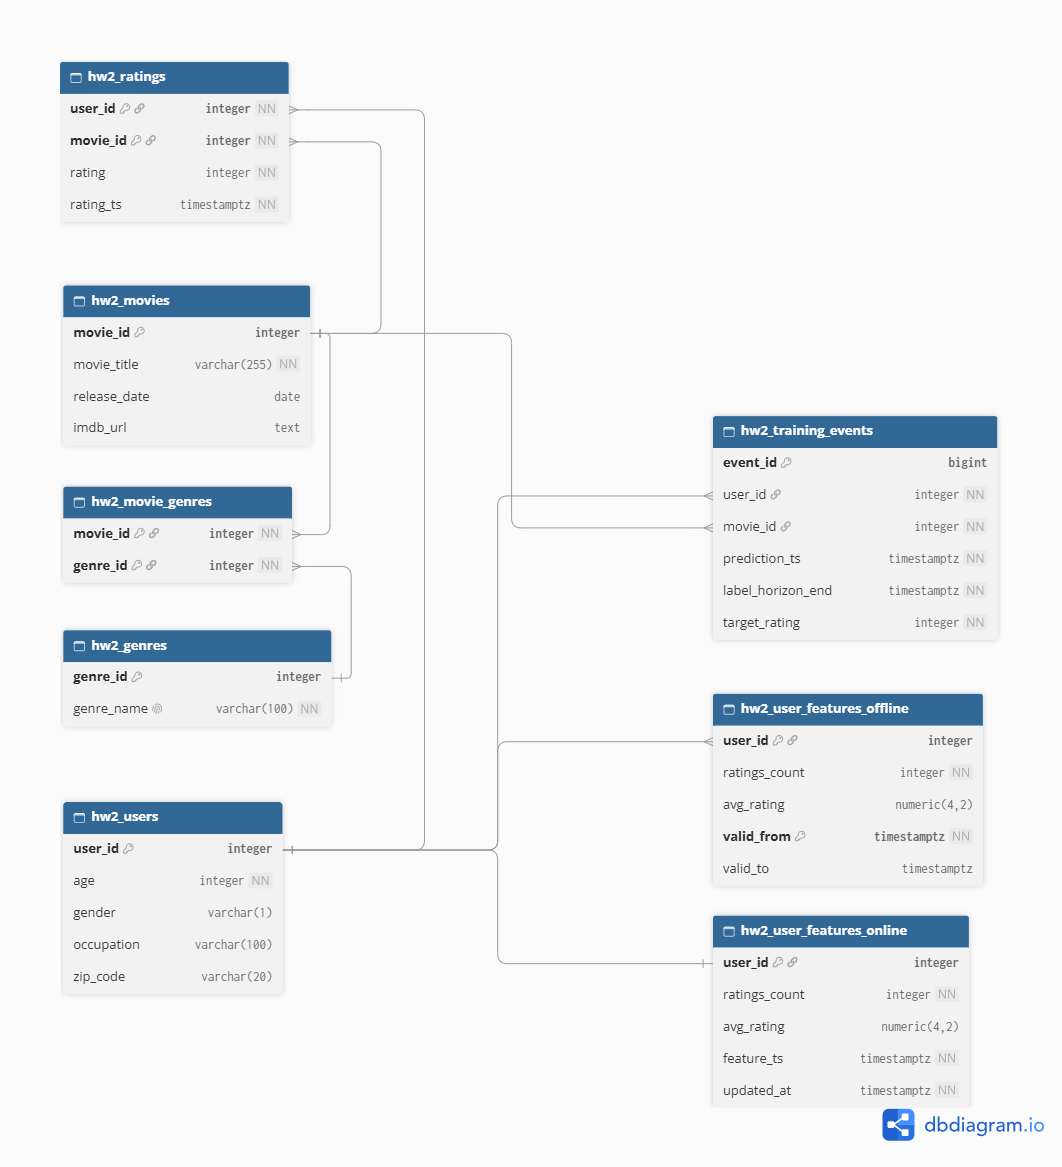

# Task 2. Prepare and Test DDL

Test `pgserver` availability and version

In [13]:
db = pgserver.get_server("/content/pgdata")

print(db.psql("SELECT version();"))

                                                  version                                                  
-----------------------------------------------------------------------------------------------------------
 PostgreSQL 16.2 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 10.2.1 20210130 (Red Hat 10.2.1-11), 64-bit
(1 row)




Save the exported DDL statements as a SQL file. Add an additional statement to drop the existing tables

In [14]:
%%writefile hw2_schema.sql

-- Set the time zone to UTC and drop previously created tables

SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_training_events,
    hw2_user_features_online,
    hw2_user_features_offline,
    hw2_movie_genres,
    hw2_ratings,
    hw2_genres,
    hw2_movies,
    hw2_users
CASCADE;

-- Insert DDL exported from dbdiagram

CREATE TABLE "hw2_users" (
  "user_id" integer PRIMARY KEY,
  "age" integer NOT NULL,
  "gender" varchar(1),
  "occupation" varchar(100),
  "zip_code" varchar(20)
);

CREATE TABLE "hw2_movies" (
  "movie_id" integer PRIMARY KEY,
  "movie_title" varchar(255) NOT NULL,
  "release_date" date,
  "imdb_url" text
);

CREATE TABLE "hw2_ratings" (
  "user_id" integer NOT NULL,
  "movie_id" integer NOT NULL,
  "rating" integer NOT NULL CHECK (rating BETWEEN 1 AND 5),
  "rating_ts" timestamptz NOT NULL,
  PRIMARY KEY ("user_id", "movie_id")
);

CREATE TABLE "hw2_genres" (
  "genre_id" integer PRIMARY KEY,
  "genre_name" varchar(100) UNIQUE NOT NULL
);

CREATE TABLE "hw2_movie_genres" (
  "movie_id" integer NOT NULL,
  "genre_id" integer NOT NULL,
  PRIMARY KEY ("movie_id", "genre_id")
);

CREATE TABLE "hw2_user_features_offline" (
  "user_id" integer,
  "ratings_count" integer NOT NULL CHECK (ratings_count >= 0),
  "avg_rating" numeric(4,2) CHECK (avg_rating BETWEEN 1 AND 5),
  "valid_from" timestamptz NOT NULL,
  "valid_to" timestamptz,
  CHECK (valid_to IS NULL OR valid_to > valid_from),
  PRIMARY KEY ("user_id", "valid_from")
);

CREATE TABLE "hw2_user_features_online" (
  "user_id" integer PRIMARY KEY,
  "ratings_count" integer NOT NULL CHECK (ratings_count >= 0),
  "avg_rating" numeric(4,2) CHECK (avg_rating BETWEEN 1 AND 5),
  "feature_ts" timestamptz NOT NULL,
  "updated_at" timestamptz NOT NULL DEFAULT (now())
);

CREATE TABLE "hw2_training_events" (
  "event_id" BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
  "user_id" integer NOT NULL,
  "movie_id" integer NOT NULL,
  "prediction_ts" timestamptz NOT NULL,
  "label_horizon_end" timestamptz NOT NULL,
  "target_rating" integer NOT NULL CHECK (target_rating BETWEEN 1 AND 5),
  CHECK (label_horizon_end > prediction_ts)
);

CREATE INDEX "hw2_idx_ratings_user_time" ON "hw2_ratings" ("user_id", "rating_ts");

ALTER TABLE "hw2_ratings" ADD FOREIGN KEY ("user_id") REFERENCES "hw2_users" ("user_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_ratings" ADD FOREIGN KEY ("movie_id") REFERENCES "hw2_movies" ("movie_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_movie_genres" ADD FOREIGN KEY ("movie_id") REFERENCES "hw2_movies" ("movie_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_movie_genres" ADD FOREIGN KEY ("genre_id") REFERENCES "hw2_genres" ("genre_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_user_features_offline" ADD FOREIGN KEY ("user_id") REFERENCES "hw2_users" ("user_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_user_features_online" ADD FOREIGN KEY ("user_id") REFERENCES "hw2_users" ("user_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_training_events" ADD FOREIGN KEY ("user_id") REFERENCES "hw2_users" ("user_id") DEFERRABLE INITIALLY IMMEDIATE;

ALTER TABLE "hw2_training_events" ADD FOREIGN KEY ("movie_id") REFERENCES "hw2_movies" ("movie_id") DEFERRABLE INITIALLY IMMEDIATE;

Overwriting hw2_schema.sql


Add a helper function to run SQL queries with ON_ERROR_STOP enabled and UTC timezone

In [15]:
def run_sql(query):
    sql = (
        "\\set ON_ERROR_STOP on\n"
        "SET TIME ZONE 'UTC';\n"
        + query
    )
    print(db.psql(sql))

Execute the DDL statements to create the database schema

In [16]:
schema_sql = Path("hw2_schema.sql").read_text(encoding="utf-8")

run_sql(schema_sql)

SET
SET
DROP TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE TABLE
CREATE INDEX
ALTER TABLE
ALTER TABLE
ALTER TABLE
ALTER TABLE
ALTER TABLE
ALTER TABLE
ALTER TABLE
ALTER TABLE



Check that all eight tables were created successfully

In [17]:
query = """
SELECT tablename
FROM pg_tables
WHERE schemaname = 'public'
  AND tablename LIKE 'hw2_%'
ORDER BY tablename;
"""

run_sql(query)

SET
         tablename         
---------------------------
 hw2_genres
 hw2_movie_genres
 hw2_movies
 hw2_ratings
 hw2_training_events
 hw2_user_features_offline
 hw2_user_features_online
 hw2_users
(8 rows)




Check timezone

In [18]:
run_sql("SHOW TIME ZONE;")

SET
 TimeZone 
----------
 UTC
(1 row)




# Task 3. Normalization and Denormalization

The business tables are designed to satisfy 3NF. Each table stores information about a specific entity or relationship, and non-key attributes depend on the corresponding primary key.

For example, `user_id` determines user attributes, while `(user_id, movie_id)` determines `rating` and `rating_ts`. Storing `movie_title` in Ratings would introduce a partial dependency on `movie_id`, violating 2NF.

In the original dataset, movie genres are represented by 19 binary columns. This does not necessarily violate 3NF, but separating Genres and Movie_Genres makes the many-to-many relationship easier to manage and extend.

The offline feature table stores historical versions identified by `(user_id, valid_from)`. The online table deliberately stores precomputed `ratings_count` and `avg_rating`. These values can be calculated from Ratings, but keeping them in a separate table allows fast lookup by `user_id`, avoids repeated aggregation of the Ratings table, and improves prediction latency.

However, storing the same feature values in multiple places creates a risk of inconsistency. For our PostgreSQL implementation, we can update offline and online features within a single transaction. The latest offline version should be published to the online table, while historical versions remain available for training. We should also track feature timestamps to prevent outdated values from replacing newer ones.

# Task 4. Point-in-Time Correctness

### 4.1. Select Sample Ratings

To keep the demonstration simple, we will use a small subset of MovieLens 100K.

First, we identify users with enough unique rating timestamps. Then we select 8 ratings from different parts of the history for each of 3 users.

This gives us 24 ratings with distinct timestamps per user.

All features in this experiment will be calculated from the selected ratings only, not from the full MovieLens dataset.

In [19]:
ratings.groupby("user_id")["timestamp"].nunique().sort_values(
    ascending=False
).head(10)

,timestamp
user_id,
655,359
279,278
276,256
416,251
92,236
393,236
13,233
222,225
450,225


In [20]:
import numpy as np

selected_users = [655, 279, 276]
samples = []

for user_id in selected_users:
    history = (
        ratings[ratings["user_id"] == user_id]
        .sort_values(["timestamp", "movie_id"])
        .drop_duplicates(subset="timestamp")
        .reset_index(drop=True)
    )

    # Select 8 ratings distributed across the user's history
    indices = np.linspace(0, len(history) - 1, 8, dtype=int)

    sample = history.iloc[indices].copy()
    samples.append(sample)

sample_ratings = pd.concat(samples, ignore_index=True)

sample_ratings["rating_ts"] = pd.to_datetime(
    sample_ratings["timestamp"],
    unit="s",
    utc=True
)

display(
    sample_ratings.sort_values(["user_id", "rating_ts"])
)

,user_id,movie_id,rating,timestamp,rating_ts
16,276,258,5,874786337,1997-09-20 20:12:17+00:00
17,276,763,3,874787214,1997-09-20 20:26:54+00:00
18,276,365,3,874791339,1997-09-20 21:35:39+00:00
19,276,96,5,874792435,1997-09-20 21:53:55+00:00
20,276,1046,3,874795772,1997-09-20 22:49:32+00:00
21,276,1074,3,877934446,1997-10-27 06:40:46+00:00
22,276,1109,3,882659656,1997-12-20 23:14:16+00:00
23,276,264,3,892436418,1998-04-13 03:00:18+00:00
8,279,288,3,875249102,1997-09-26 04:45:02+00:00
9,279,1093,4,875298330,1997-09-26 18:25:30+00:00


In [21]:
# Number of selected ratings per user
print(sample_ratings.groupby("user_id").size())

# Minimum interval between selected ratings, in seconds
time_gaps = (
    sample_ratings
    .sort_values(["user_id", "timestamp"])
    .groupby("user_id")["timestamp"]
    .diff()
)

print("Minimum gap (seconds):", time_gaps.min())

user_id
276    8
279    8
655    8
dtype: int64
Minimum gap (seconds): 877.0


### 4.2. Create Historical Feature Versions

For each user, we calculate two cumulative features:

ratings_count — number of ratings in the selected history;

avg_rating — average rating in the selected history.

We create 4 historical versions per user, after ratings 1, 3, 5, and 7.

Each version becomes available one second after the corresponding rating. valid_to is set to the beginning of the next version, while the latest version has NULL as valid_to.

These timestamps simulate feature publication. Versions use non-overlapping intervals [valid_from, valid_to).

In [22]:
# Sort ratings and assign a sequential number
work = sample_ratings.sort_values(
    ["user_id", "rating_ts", "movie_id"]
).copy()

work["rating_no"] = work.groupby("user_id").cumcount() + 1

# Calculate cumulative features
work["ratings_count"] = work["rating_no"]

work["avg_rating"] = (
    work.groupby("user_id")["rating"]
    .transform(lambda s: s.expanding().mean())
    .round(2)
)

# Select four snapshots per user
snapshots = work[
    work["rating_no"].isin([1, 3, 5, 7])
].copy()

# Publish each snapshot one second after its source rating
snapshots["valid_from"] = (
    snapshots["rating_ts"] + pd.Timedelta(seconds=1)
)

# End each version when the next version begins
snapshots["valid_to"] = (
    snapshots.groupby("user_id")["valid_from"].shift(-1)
)

snapshots = snapshots[
    ["user_id", "ratings_count", "avg_rating",
     "valid_from", "valid_to"]
]

display(snapshots)

,user_id,ratings_count,avg_rating,valid_from,valid_to
16,276,1,5.00,1997-09-20 20:12:18+00:00,1997-09-20 21:35:40+00:00
18,276,3,3.67,1997-09-20 21:35:40+00:00,1997-09-20 22:49:33+00:00
20,276,5,3.80,1997-09-20 22:49:33+00:00,1997-12-20 23:14:17+00:00
22,276,7,3.57,1997-12-20 23:14:17+00:00,NaT
8,279,1,3.00,1997-09-26 04:45:03+00:00,1997-09-26 21:41:42+00:00
10,279,3,3.67,1997-09-26 21:41:42+00:00,1997-10-28 23:52:32+00:00
12,279,5,3.40,1997-10-28 23:52:32+00:00,1998-03-19 04:36:23+00:00
14,279,7,3.43,1998-03-19 04:36:23+00:00,NaT
0,655,1,4.00,1998-02-14 02:52:01+00:00,1998-02-14 04:15:59+00:00
2,655,3,3.00,1998-02-14 04:15:59+00:00,1998-02-14 20:56:33+00:00


### 4.3. Prepare Training Events

For each user, we select ratings 4 and 8 as target events.

Since MovieLens does not contain actual prediction timestamps, we simulate prediction_ts one second before the corresponding rating. We also define a one-day label horizon.

This gives us 6 training events. The target rating becomes known after the prediction timestamp and must not be included in the features used for that prediction.

In [23]:
training_events = work[
    work["rating_no"].isin([4, 8])
].copy()

training_events["prediction_ts"] = (
    training_events["rating_ts"] - pd.Timedelta(seconds=1)
)

training_events["label_horizon_end"] = (
    training_events["prediction_ts"] + pd.Timedelta(days=1)
)

training_events = (
    training_events
    .rename(columns={"rating": "target_rating"})
    [
        ["user_id", "movie_id", "prediction_ts",
         "label_horizon_end", "target_rating"]
    ]
)

display(training_events)

,user_id,movie_id,prediction_ts,label_horizon_end,target_rating
19,276,96,1997-09-20 21:53:54+00:00,1997-09-21 21:53:54+00:00,5
23,276,264,1998-04-13 03:00:17+00:00,1998-04-14 03:00:17+00:00,3
11,279,1481,1997-09-26 22:45:24+00:00,1997-09-27 22:45:24+00:00,4
15,279,269,1998-04-18 02:11:31+00:00,1998-04-19 02:11:31+00:00,4
3,655,223,1998-02-14 16:30:55+00:00,1998-02-15 16:30:55+00:00,3
7,655,131,1998-04-19 16:11:22+00:00,1998-04-20 16:11:22+00:00,2


### 4.4. Prepare Online Features and Business Data

The online feature store contains the latest published feature version for each user.

We also select the corresponding Users and Movies records to preserve referential integrity.

Movie genre flags are converted into Movie_Genres records using melt(), and movie release dates are converted into a PostgreSQL-compatible format.

In [24]:
online_features = (
    snapshots
    .sort_values(["user_id", "valid_from"])
    .drop_duplicates(subset="user_id", keep="last")
    .copy()
)

online_features["feature_ts"] = online_features["valid_from"]

online_features = online_features[
    ["user_id", "ratings_count", "avg_rating", "feature_ts"]
]

display(online_features)

,user_id,ratings_count,avg_rating,feature_ts
22,276,7,3.57,1997-12-20 23:14:17+00:00
14,279,7,3.43,1998-03-19 04:36:23+00:00
6,655,7,2.71,1998-03-03 02:48:34+00:00


In [25]:
selected_user_ids = sample_ratings["user_id"].unique()
selected_movie_ids = sample_ratings["movie_id"].unique()

users_subset = users[
    users["user_id"].isin(selected_user_ids)
].copy()

movies_subset = movies[
    movies["movie_id"].isin(selected_movie_ids)
].copy()

print("Users:", len(users_subset))
print("Movies:", len(movies_subset))
print("Ratings:", len(sample_ratings))

Users: 3
Movies: 24
Ratings: 24


In [26]:
movie_genres = (
    movies_subset[["movie_id", *genre_columns]]
    .melt(
        id_vars="movie_id",
        var_name="genre_name",
        value_name="is_genre"
    )
    .query("is_genre == 1")
    .merge(
        genres[["genre_id", "genre_name"]],
        on="genre_name",
        validate="many_to_one"
    )
    [["movie_id", "genre_id"]]
    .sort_values(["movie_id", "genre_id"])
    .reset_index(drop=True)
)

display(movie_genres.head(15))

print("Movie-genre relations:", len(movie_genres))
print("Movies covered:", movie_genres["movie_id"].nunique())
print("Duplicate relations:", movie_genres.duplicated().sum())

,movie_id,genre_id
0,92,1
1,92,6
2,92,14
3,96,1
4,96,15
5,96,16
6,131,8
7,131,14
8,161,1
9,161,14


Movie-genre relations: 49
Movies covered: 24
Duplicate relations: 0


In [27]:
movies_db = movies_subset[
    ["movie_id", "movie_title", "release_date", "IMDb_URL"]
].copy()

movies_db = movies_db.rename(
    columns={"IMDb_URL": "imdb_url"}
)

movies_db["release_date"] = pd.to_datetime(
    movies_db["release_date"],
    format="%d-%b-%Y",
    errors="coerce"
).dt.strftime("%Y-%m-%d")

display(movies_db.head())

,movie_id,movie_title,release_date,imdb_url
91,92,True Romance (1993),1993-01-01,http://us.imdb.com/M/title-exact?True%20Romanc...
95,96,Terminator 2: Judgment Day (1991),1991-01-01,http://us.imdb.com/M/title-exact?Terminator%20...
130,131,Breakfast at Tiffany's (1961),1961-01-01,http://us.imdb.com/M/title-exact?Breakfast%20a...
160,161,Top Gun (1986),1986-01-01,http://us.imdb.com/M/title-exact?Top%20Gun%20(...
171,172,"Empire Strikes Back, The (1980)",1980-01-01,http://us.imdb.com/M/title-exact?Empire%20Stri...


### 4.5. Load and Verify Test Data

We generate SQL INSERT statements from the prepared DataFrames and load the records into PostgreSQL in a single transaction.

Finally, we check the number of records in each table to confirm that the test dataset was loaded successfully.

In [28]:
def sql_value(value):
    if pd.isna(value):
        return "NULL"

    if isinstance(value, pd.Timestamp):
        return "'" + value.isoformat() + "'"

    if isinstance(value, str):
        return "'" + value.replace("'", "''") + "'"

    return str(value)


def build_insert(table_name, df):
    columns = ", ".join(df.columns)

    rows = []
    for row in df.itertuples(index=False, name=None):
        values = ", ".join(sql_value(value) for value in row)
        rows.append(f"({values})")

    return (
        f"INSERT INTO {table_name} ({columns}) VALUES\n"
        + ",\n".join(rows)
        + ";"
    )

In [29]:
tables_to_load = {
    "hw2_users": users_subset[
        ["user_id", "age", "gender", "occupation", "zip_code"]
    ],
    "hw2_movies": movies_db,
    "hw2_genres": genres[
        ["genre_id", "genre_name"]
    ],
    "hw2_ratings": sample_ratings[
        ["user_id", "movie_id", "rating", "rating_ts"]
    ],
    "hw2_movie_genres": movie_genres,
    "hw2_user_features_offline": snapshots,
    "hw2_user_features_online": online_features,
    "hw2_training_events": training_events
}

insert_statements = [
    build_insert(table_name, df)
    for table_name, df in tables_to_load.items()
]

load_sql = (
    "BEGIN;\n"
    + "\n\n".join(insert_statements)
    + "\nCOMMIT;"
)

run_sql(load_sql)

SET
BEGIN
INSERT 0 3
INSERT 0 24
INSERT 0 19
INSERT 0 24
INSERT 0 49
INSERT 0 12
INSERT 0 3
INSERT 0 6
COMMIT



In [30]:
query = """
SELECT 'users' AS entity, COUNT(*) FROM hw2_users
UNION ALL
SELECT 'movies', COUNT(*) FROM hw2_movies
UNION ALL
SELECT 'genres', COUNT(*) FROM hw2_genres
UNION ALL
SELECT 'ratings', COUNT(*) FROM hw2_ratings
UNION ALL
SELECT 'movie_genres', COUNT(*) FROM hw2_movie_genres
UNION ALL
SELECT 'offline_features', COUNT(*) FROM hw2_user_features_offline
UNION ALL
SELECT 'online_features', COUNT(*) FROM hw2_user_features_online
UNION ALL
SELECT 'training_events', COUNT(*) FROM hw2_training_events;
"""

run_sql(query)

SET
      entity      | count 
------------------+-------
 users            |     3
 movies           |    24
 genres           |    19
 ratings          |    24
 movie_genres     |    49
 offline_features |    12
 online_features  |     3
 training_events  |     6
(8 rows)




### 4.6. AS-OF Lookup at a Specific Timestamp

This query retrieves the feature version that was valid for user 276 at a specific prediction timestamp.

The expected result is one row with `ratings_count = 3` and `avg_rating = 3.67`.

In [31]:
query = """
SELECT *
FROM hw2_user_features_offline
WHERE user_id=276
  AND valid_from <= TIMESTAMPTZ '1997-09-20 21:53:54+00'
  AND (
    valid_to > TIMESTAMPTZ '1997-09-20 21:53:54+00'
    OR valid_to IS NULL
  );
"""

run_sql(query)

SET
 user_id | ratings_count | avg_rating |       valid_from       |        valid_to        
---------+---------------+------------+------------------------+------------------------
     276 |             3 |       3.67 | 1997-09-20 21:35:40+00 | 1997-09-20 22:49:33+00
(1 row)




### 4.7. AS-OF Lookup at a Version Boundary

This query checks the boundary between two feature versions.

At the exact transition timestamp, the previous version is excluded and the new version is selected. This confirms the use of half-open validity intervals `[valid_from, valid_to)`.

In [32]:
query = """
SELECT *
FROM hw2_user_features_offline
WHERE user_id=276
  AND valid_from <= TIMESTAMPTZ '1997-09-20 21:35:40+00'
  AND (
    valid_to > TIMESTAMPTZ '1997-09-20 21:35:40+00'
    OR valid_to IS NULL
  );
"""

run_sql(query)

SET
 user_id | ratings_count | avg_rating |       valid_from       |        valid_to        
---------+---------------+------------+------------------------+------------------------
     276 |             3 |       3.67 | 1997-09-20 21:35:40+00 | 1997-09-20 22:49:33+00
(1 row)




### 4.8. AS-OF JOIN with Training Events

This query joins training events with historical user features using prediction_ts. For each event, we select the feature version that was valid at the prediction time. We use LEFT JOIN to preserve events even if no matching features are available. The query returns 6 training events with their corresponding historical features, without including future feature versions.

In [33]:
query = """
SELECT e.event_id, e.user_id, e.movie_id, e.prediction_ts, e.target_rating, f.ratings_count, f.avg_rating
FROM hw2_training_events AS e
LEFT JOIN hw2_user_features_offline AS f
	ON f.user_id = e.user_id
	AND f.valid_from <= e.prediction_ts
	AND (
		f.valid_to > e.prediction_ts
		OR f.valid_to IS NULL
	)
ORDER BY e.event_id;
"""

run_sql(query)

SET
 event_id | user_id | movie_id |     prediction_ts      | target_rating | ratings_count | avg_rating 
----------+---------+----------+------------------------+---------------+---------------+------------
        1 |     276 |       96 | 1997-09-20 21:53:54+00 |             5 |             3 |       3.67
        2 |     276 |      264 | 1998-04-13 03:00:17+00 |             3 |             7 |       3.57
        3 |     279 |     1481 | 1997-09-26 22:45:24+00 |             4 |             3 |       3.67
        4 |     279 |      269 | 1998-04-18 02:11:31+00 |             4 |             7 |       3.43
        5 |     655 |      223 | 1998-02-14 16:30:55+00 |             3 |             3 |       3.00
        6 |     655 |      131 | 1998-04-19 16:11:22+00 |             2 |             7 |       2.71
(6 rows)




### 4.9. Check for Overlapping Intervals

This query uses a self-join to detect overlapping feature validity intervals for the same user. Each pair of different versions is compared only once. The expected result is zero rows, confirming that no overlapping intervals were found.

In [34]:
query = """
SELECT
    f.user_id,
    f.valid_from AS f_from,
    f.valid_to AS f_to,
    e.valid_from AS e_from,
    e.valid_to AS e_to
FROM hw2_user_features_offline AS f
JOIN hw2_user_features_offline AS e
    ON f.user_id = e.user_id
    AND f.valid_from < e.valid_from
    AND (f.valid_from < e.valid_to OR e.valid_to IS NULL)
    AND (e.valid_from < f.valid_to OR f.valid_to IS NULL);
"""

run_sql(query)

SET
 user_id | f_from | f_to | e_from | e_to 
---------+--------+------+--------+------
(0 rows)




### 4.10. Demonstrate Data Leakage

To demonstrate the importance of temporal conditions, we intentionally join training events with historical features using only `user_id`.

Without checking the validity intervals, a training event may be joined with multiple feature versions, including versions published after its prediction timestamp.

This can introduce future information into the training data (data leakage) and produce duplicated training records.

In [35]:
query = """
SELECT
    e.event_id,
    e.user_id,
    e.prediction_ts,
    f.valid_from,
    f.ratings_count,
    f.avg_rating,
    (f.valid_from > e.prediction_ts) AS from_future
FROM hw2_training_events AS e
JOIN hw2_user_features_offline AS f
    ON e.user_id = f.user_id
ORDER BY e.event_id, f.valid_from;
"""

run_sql(query)

SET
 event_id | user_id |     prediction_ts      |       valid_from       | ratings_count | avg_rating | from_future 
----------+---------+------------------------+------------------------+---------------+------------+-------------
        1 |     276 | 1997-09-20 21:53:54+00 | 1997-09-20 20:12:18+00 |             1 |       5.00 | f
        1 |     276 | 1997-09-20 21:53:54+00 | 1997-09-20 21:35:40+00 |             3 |       3.67 | f
        1 |     276 | 1997-09-20 21:53:54+00 | 1997-09-20 22:49:33+00 |             5 |       3.80 | t
        1 |     276 | 1997-09-20 21:53:54+00 | 1997-12-20 23:14:17+00 |             7 |       3.57 | t
        2 |     276 | 1998-04-13 03:00:17+00 | 1997-09-20 20:12:18+00 |             1 |       5.00 | f
        2 |     276 | 1998-04-13 03:00:17+00 | 1997-09-20 21:35:40+00 |             3 |       3.67 | f
        2 |     276 | 1998-04-13 03:00:17+00 | 1997-09-20 22:49:33+00 |             5 |       3.80 | f
        2 |     276 | 1998-04-13 03:00:17+00 | 

To summarize the results, we count the total number of joined rows and the number of rows containing feature versions published after `prediction_ts`.

In [36]:
query = """
SELECT
    COUNT(*) AS joined_rows,
    COUNT(*) FILTER (
        WHERE f.valid_from > e.prediction_ts
    ) AS future_rows
FROM hw2_training_events AS e
JOIN hw2_user_features_offline AS f
    ON e.user_id = f.user_id;
"""

run_sql(query)

SET
 joined_rows | future_rows 
-------------+-------------
          24 |           6
(1 row)




The incorrect JOIN returns 24 rows instead of 6, including 6 rows with feature versions published after the corresponding prediction timestamps. Such future features could introduce data leakage during model training. The correct AS-OF JOIN prevents this by selecting only the version valid at prediction_ts.

# Task 5. Reflection

The most challenging part of this homework was designing the ML-related tables and understanding how they interact with the business data. I also needed more practice with functional dependencies and normalization. A simple AS-OF SELECT was relatively straightforward, but the AS-OF JOIN was harder because each training event has its own prediction timestamp and must be matched with the correct historical feature version.

For the business layer, I separated users, movies, ratings, and genres into related tables. I also used a bridge table for the many-to-many relationship between movies and genres. For the ML layer, I chose to store precomputed `ratings_count` and `avg_rating` features. This makes online lookups simpler and avoids repeatedly aggregating the Ratings table, but it requires extra storage and careful synchronization between offline and online data.

To keep the experiment manageable, I used 24 selected ratings from three MovieLens users instead of the full dataset. I created synthetic prediction timestamps and feature publication times. This approach made it easier to check the expected results, although it does not represent a real recommendation workflow. The incorrect JOIN demonstrated why time conditions matter: it returned multiple feature versions for each event, including values published after prediction time.

If the system had to serve many users and frequent predictions, I would keep the indexed lookup by `user_id` and consider caching or a dedicated key-value store. I would also monitor feature freshness and update aggregates efficiently.

Schema evolution would require similar care. When adding new features, I would update both stores, backfill historical values using only information available at each point in time, and maintain compatibility with models that use older feature definitions.